# Subgroup Sensitivity Analysis — CKD (Scenario B)

## Changes from v6

| # | 항목 | 변경 내용 |
|---|------|-----------|
| 1 | AUROC 축 레이블 | bold + 16pt |
| 2 | Subgroup ↔ N/Events 간격 | nx: xmin-0.04 → xmin-0.01 (더 좁게) |
| 3 | P 헤더 | 'P for heterogeneity' → 'P for difference / between group' (2줄) |
| 4 | 제목 | ax.title → fig.suptitle (헤더와 겹침 방지) |


In [2]:
"""
3_subgroup_analysis_CKD_v3.py
Scenario B (full cohort, MICE + aux) subgroup sensitivity analysis.

Changes from v2
───────────────
1. Scenario A → Scenario B throughout
   - load_reloaded_models(): models/scenario_B/
   - reconstruct_splits(): is_cap_era() filter removed; imp_B.transform() applied
2. map_sex_to_binary() removed (Sex already stored as 1.0/2.0 in v4-2)
   - coerce_feature_columns_numeric() Sex branch removed
3. TwoTierImputer import added before any joblib.load() call
4. load_imputer() helper added
5. Metadata updated to reflect Scenario B
"""

from __future__ import annotations

import json
import re
import sys
import warnings
from pathlib import Path
from typing import Dict, List, Tuple

import joblib
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from sklearn.experimental import enable_iterative_imputer  # noqa
from sklearn.metrics import roc_auc_score
from sklearn.model_selection import train_test_split
from sklearn.pipeline import Pipeline

try:
    import statsmodels.api as sm
except Exception as e:
    sm = None
    _STATSMODELS_IMPORT_ERROR = e
else:
    _STATSMODELS_IMPORT_ERROR = None

from tabpfn.model_loading import load_fitted_tabpfn_model

# =============================================================================
# USER CONFIG
# =============================================================================
DATA_PATH     = Path("/home/ubuntu/Fibroscan_CKD_2025.xlsx")
RUN_DIR       = Path("/home/ubuntu/ckd_output")

OUTCOME       = "CKD"
N_BOOT        = 1000
RANDOM_STATE  = 42
HOSP_INTERNAL = 10
HOSP_EXTERNAL = 20
FIVE_YEARS_DAYS        = 365 * 5 + 1
MIN_FU_DAYS_FOR_COHORT = 365

# [수정 1] Scenario B
OUTPUT_DIRNAME = "subgroup_sensitivity_scen_B"

DECILES_FOR_CALIBRATION = 10

MODEL_SPECS = {
    "base":         ["Age", "Sex", "BMI", "HTN", "DM", "Baseline_Cr"],
    "base_lsm":     ["Age", "Sex", "BMI", "HTN", "DM", "Baseline_Cr", "LSM_kPa"],
    "base_lsm_cap": ["Age", "Sex", "BMI", "HTN", "DM", "Baseline_Cr", "LSM_kPa", "CAP"],
}

AGE_COL = "Age"
SEX_COL = "Sex"
LSM_COL = "LSM_kPa"
CAP_COL = "CAP"
FU_COL  = "Follow-up_duration"

# CAP MNAR cutoffs (기관별) — imputer 로딩 전 참조용
CAP_CUTOFF_BY_HOSPITAL = {
    10: pd.Timestamp("2012-03-14"),
    20: pd.Timestamp("2013-01-10"),
}

# Steatosis 기준 (Table 1과 동일)
CAP_STEATOSIS_CUTOFF = 238   # dB/m
CAP_REVIEWER_CUTOFF  = 275   # dB/m

# [수정 3] TwoTierImputer — joblib.load 전에 반드시 import
# models/src/two_tier_imputer.py 를 sys.path에 등록
_SRC_DIR = str(RUN_DIR / "models" / "src")
if _SRC_DIR not in sys.path:
    sys.path.insert(0, _SRC_DIR)

try:
    from two_tier_imputer import TwoTierImputer  # noqa: F401 — pickle 역직렬화 필수
    import __main__
    if not hasattr(__main__, "TwoTierImputer"):
        __main__.TwoTierImputer = TwoTierImputer
    print(f"[INIT] TwoTierImputer imported from: {sys.modules['two_tier_imputer'].__file__}")
except ImportError as e:
    raise ImportError(
        f"two_tier_imputer.py를 찾을 수 없습니다.\n"
        f"  탐색 경로: {_SRC_DIR}\n"
        f"  해결: {_SRC_DIR} 에 two_tier_imputer.py 복사\n"
        f"  오류: {e}"
    ) from e

EPS = 1e-12


# =============================================================================
# HELPERS
# =============================================================================

# [수정 2] map_sex_to_binary 제거 — Sex는 이미 1.0/2.0으로 저장됨

def coerce_feature_columns_numeric(dfs: List[pd.DataFrame], feature_cols: List[str]):
    """[수정 2] Sex 분기 제거 — pd.to_numeric 일괄 적용"""
    for df in dfs:
        if df is None:
            continue
        for c in feature_cols:
            if c in df.columns:
                df[c] = pd.to_numeric(df[c], errors="coerce")


def compute_steatosis_flag(df: pd.DataFrame, cutoff: int = CAP_STEATOSIS_CUTOFF) -> pd.Series:
    """
    복합 Steatosis 정의 (cutoff 파라미터화).
    우선순위: CAP >= cutoff → NAFLD_ICD == 1 → FattyLiver_US / FattyLiver_CT
    동일한 로직으로 CAP 238 (primary) 및 CAP 275 (sensitivity) 모두 지원.
    """
    cap_series = (
        pd.to_numeric(df["CAP"], errors="coerce")
        if "CAP" in df.columns
        else pd.Series(np.nan, index=df.index)
    )
    has_cap   = cap_series.notna()
    cap_fatty = (cap_series >= cutoff).fillna(False)

    icd_fatty = (
        pd.to_numeric(df["NAFLD_ICD"], errors="coerce").fillna(0) == 1
        if "NAFLD_ICD" in df.columns
        else pd.Series(False, index=df.index)
    )

    imaging_components = []
    for c in ["FattyLiver_US", "FattyLiver_CT"]:
        if c in df.columns:
            imaging_components.append(pd.to_numeric(df[c], errors="coerce").fillna(0))
    imaging_fatty = (
        (sum(imaging_components) > 0)
        if imaging_components
        else pd.Series(False, index=df.index)
    )

    return pd.Series(
        np.where(has_cap, cap_fatty, np.where(icd_fatty, icd_fatty, imaging_fatty)),
        index=df.index,
        dtype=bool,
    )


def apply_cohort_exclusions(df: pd.DataFrame) -> pd.DataFrame:
    out = df.copy()
    for col in ["Baseline_eGFR", "ESRD", "KT", "Baseline_PU", "Malignancy", "Follow-up_duration"]:
        if col in out.columns:
            out[col] = pd.to_numeric(out[col], errors="coerce")
    mask = pd.Series(True, index=out.index)
    if "Baseline_eGFR"      in out.columns: mask &= ~(out["Baseline_eGFR"] < 60)
    if "ESRD"               in out.columns: mask &= ~(out["ESRD"] == 1)
    if "KT"                 in out.columns: mask &= ~(out["KT"] == 1)
    if "Baseline_PU"        in out.columns: mask &= ~(out["Baseline_PU"] == 1)
    if "Malignancy"         in out.columns: mask &= ~(out["Malignancy"] == 1)
    if "Follow-up_duration" in out.columns:
        mask &= ~(out["Follow-up_duration"] < MIN_FU_DAYS_FOR_COHORT)
    return out.loc[mask].reset_index(drop=True)


def build_5yr_outcome(df, event_col, tte_col, fu_col=FU_COL, five_year_days=FIVE_YEARS_DAYS):
    out = df.copy()
    for col in [event_col, tte_col, fu_col]:
        out[col] = pd.to_numeric(out[col], errors="coerce")
    has_fu     = out[fu_col].notna()
    event_is_1 = out[event_col] == 1
    cand = out.loc[has_fu & ((~event_is_1) | out[tte_col].notna())].copy()
    y = pd.Series(np.nan, index=cand.index, dtype=float)
    y.loc[(cand[event_col] == 1) & (cand[tte_col] > 0) & (cand[tte_col] <= five_year_days)] = 1
    y.loc[(cand[event_col] == 0) & (cand[fu_col] >= five_year_days)] = 0
    y.loc[
        (cand[event_col] == 1) & (cand[tte_col] > five_year_days) & (cand[fu_col] >= five_year_days)
    ] = 0
    cand = cand.loc[y.notna()].copy()
    cand["y"] = y.loc[cand.index].astype(int)
    return cand.reset_index(drop=True)


def add_fibroscan_date_numeric(
    df: pd.DataFrame,
    ref: pd.Timestamp = pd.Timestamp("2000-01-01"),
) -> pd.DataFrame:
    """Scenario B MICE 보조변수 — imputer.transform() 전에 필요."""
    df = df.copy()
    df["Fibroscan_Date_numeric"] = (
        pd.to_datetime(df["Fibroscan_Date"], errors="coerce") - ref
    ).dt.days.astype(float)
    return df


def _clip_prob(p): return np.clip(np.asarray(p, dtype=float), EPS, 1 - EPS)
def _logit(p):     p = _clip_prob(p); return np.log(p / (1 - p))


def stratified_bootstrap_auc_ci(y_true, p_hat, n_boot=1000, seed=42):
    y_true = np.asarray(y_true).astype(int)
    p_hat  = np.asarray(p_hat, dtype=float)
    if len(y_true) == 0 or len(np.unique(y_true)) < 2:
        return np.nan, np.nan, np.nan
    auc = roc_auc_score(y_true, p_hat)
    rng  = np.random.default_rng(seed)
    idx0, idx1 = np.where(y_true == 0)[0], np.where(y_true == 1)[0]
    dist = []
    for _ in range(n_boot):
        idx = np.concatenate(
            [rng.choice(idx0, len(idx0), replace=True), rng.choice(idx1, len(idx1), replace=True)]
        )
        rng.shuffle(idx)
        yb, pb = y_true[idx], p_hat[idx]
        if len(np.unique(yb)) < 2:
            continue
        dist.append(roc_auc_score(yb, pb))
    if not dist:
        return float(auc), np.nan, np.nan
    lo, hi = np.quantile(dist, [0.025, 0.975])
    return float(auc), float(lo), float(hi)


def hetero_pvalue_binary(y_true, p_hat, subgroup_binary) -> float:
    if sm is None:
        raise ImportError(f"statsmodels import failed: {_STATSMODELS_IMPORT_ERROR}")
    tmp = pd.DataFrame(
        {"y": np.asarray(y_true).astype(int), "lp": _logit(p_hat),
         "g": pd.to_numeric(subgroup_binary, errors="coerce")}
    ).dropna()
    if tmp.empty or tmp["g"].nunique() < 2 or tmp["y"].nunique() < 2:
        return np.nan
    tmp["lp_x_g"] = tmp["lp"] * tmp["g"]
    X = sm.add_constant(tmp[["lp", "g", "lp_x_g"]], has_constant="add")
    try:
        fit = sm.Logit(tmp["y"], X).fit(disp=False, maxiter=200)
        return float(fit.pvalues.get("lp_x_g", np.nan))
    except Exception:
        try:
            fit = sm.GLM(tmp["y"], X, family=sm.families.Binomial()).fit()
            return float(fit.pvalues.get("lp_x_g", np.nan))
        except Exception:
            return np.nan


def calibration_intercept_slope(y_true, p_hat):
    if sm is None:
        raise ImportError(f"statsmodels import failed: {_STATSMODELS_IMPORT_ERROR}")
    tmp = pd.DataFrame({"y": np.asarray(y_true).astype(int), "lp": _logit(p_hat)}).dropna()
    if tmp.empty or tmp["y"].nunique() < 2:
        return np.nan, np.nan
    X = sm.add_constant(tmp[["lp"]], has_constant="add")
    try:
        fit = sm.Logit(tmp["y"], X).fit(disp=False, maxiter=200)
        return float(fit.params.get("const", np.nan)), float(fit.params.get("lp", np.nan))
    except Exception:
        try:
            fit = sm.GLM(tmp["y"], X, family=sm.families.Binomial()).fit()
            return float(fit.params.get("const", np.nan)), float(fit.params.get("lp", np.nan))
        except Exception:
            return np.nan, np.nan


def oe_ratio(y_true, p_hat) -> float:
    obs = float(np.sum(np.asarray(y_true).astype(int)))
    exp = float(np.sum(np.asarray(p_hat, dtype=float)))
    return np.nan if exp <= 0 else obs / exp


def make_decile_table(y_true, p_hat, n_bins=10) -> pd.DataFrame:
    tmp = pd.DataFrame(
        {"y": np.asarray(y_true).astype(int), "p": np.asarray(p_hat, dtype=float)}
    ).dropna()
    if tmp.empty:
        return pd.DataFrame()
    try:
        tmp["bin"] = pd.qcut(tmp["p"], q=min(n_bins, tmp["p"].nunique()), duplicates="drop")
    except Exception:
        return pd.DataFrame()
    out = (
        tmp.groupby("bin", observed=False)
        .agg(
            n=("y", "size"),
            observed_rate=("y", "mean"),
            predicted_mean=("p", "mean"),
            pred_min=("p", "min"),
            pred_max=("p", "max"),
        )
        .reset_index(drop=True)
    )
    out.insert(0, "decile_order", np.arange(1, len(out) + 1))
    return out


def save_calibration_plot(decile_df, title, out_path):
    if decile_df.empty:
        return
    out_path.parent.mkdir(parents=True, exist_ok=True)
    fig, ax = plt.subplots(figsize=(5.2, 5.2))
    ax.plot([0, 1], [0, 1], linestyle="--", linewidth=1)
    ax.plot(decile_df["predicted_mean"], decile_df["observed_rate"], marker="o", linewidth=1.5)
    maxv = float(decile_df[["predicted_mean", "observed_rate"]].max().max())
    ax.set_xlim(0, max(0.05, maxv * 1.05))
    ax.set_ylim(0, max(0.05, maxv * 1.05))
    ax.set_xlabel("Mean predicted risk")
    ax.set_ylabel("Observed event rate")
    ax.set_title(title)
    fig.tight_layout()
    fig.savefig(out_path, dpi=220, bbox_inches="tight")
    plt.close(fig)


# =============================================================================
# DATA LOADING & SPLIT RECONSTRUCTION
# =============================================================================

def load_raw_data(path: Path) -> pd.DataFrame:
    if not path.exists():
        raise FileNotFoundError(f"Raw data not found: {path}")
    if path.suffix.lower() in [".xlsx", ".xls"]:
        return pd.read_excel(path)
    if path.suffix.lower() == ".csv":
        return pd.read_csv(path)
    raise ValueError(f"Unsupported file format: {path.suffix}")


def load_imputer(path: Path):
    """
    [수정 3] TwoTierImputer joblib.load.
    반드시 TwoTierImputer import 후 호출해야 함 (모듈 상단에서 처리됨).
    """
    if not path.exists():
        raise FileNotFoundError(f"Imputer not found: {path}")
    return joblib.load(path)


def reconstruct_splits(df_raw: pd.DataFrame, outcome: str, imp_B):
    """
    [수정 1] Scenario B cohort 재현:
      1. 전체 코호트 exclusion + outcome labeling
      2. H10/H20 분리 및 80:20 internal split (동일 random_state)
      3. is_cap_era() 필터 제거 → 전체 코호트 유지
      4. Fibroscan_Date_numeric 추가 (MICE 보조변수)
      5. imp_B.transform() 으로 CAP MICE 대치 적용

    Scenario A와의 차이:
      - CAP-era 필터 없음 (n 약 2배)
      - CAP 결측값이 MICE로 대치됨 (Hospital + Fibroscan_Date_numeric 보조)
    """
    if outcome == "CKD":
        event_col, tte_col = "CKD", "TTO_CKD"
    elif outcome == "eGFR25":
        event_col, tte_col = "eGFR25", "TTO_eGFR25"
    else:
        raise ValueError("OUTCOME must be 'CKD' or 'eGFR25'")

    df_excl  = apply_cohort_exclusions(df_raw)
    df_final = build_5yr_outcome(df_excl, event_col=event_col, tte_col=tte_col)

    internal = df_final[df_final["Hospital"] == HOSP_INTERNAL].copy()
    external = df_final[df_final["Hospital"] == HOSP_EXTERNAL].copy()

    idx_train, idx_test = train_test_split(
        internal.index.values,
        test_size=0.2,
        random_state=RANDOM_STATE,
        stratify=internal["y"].astype(int).values,
    )
    df_test = internal.loc[idx_test].copy()
    df_ext  = external.copy()

    # ── Scenario B: CAP-era 필터 없음 ─────────────────────────────────────
    # (Scenario A와 달리 is_cap_era() 필터 적용하지 않음)

    # ── Fibroscan_Date_numeric 추가 (MICE 보조변수) ────────────────────────
    df_test = add_fibroscan_date_numeric(df_test)
    df_ext  = add_fibroscan_date_numeric(df_ext)

    # ── imp_B.transform() — CAP MICE 대치 ────────────────────────────────
    print("[IMPUTE] Applying imp_B.transform() to internal_test ...")
    df_test = imp_B.transform(df_test)

    print("[IMPUTE] Applying imp_B.transform() to external ...")
    df_ext  = imp_B.transform(df_ext)

    # ── Post-imputation 결측 확인 ─────────────────────────────────────────
    all_feats = sorted(set(sum(MODEL_SPECS.values(), [])))
    for label, df_ in [("internal_test", df_test), ("external", df_ext)]:
        missing = {c: int(df_[c].isna().sum()) for c in all_feats if c in df_.columns and df_[c].isna().any()}
        if missing:
            print(f"  [{label}] ⚠️  residual missing: {missing}")
        else:
            print(f"  [{label}] ✅ no missing in model features")

    print(f"\n[INFO] Scenario B splits:")
    print(f"  internal_test  n={len(df_test):,}  event={df_test['y'].mean():.3f}")
    print(f"  external       n={len(df_ext):,}   event={df_ext['y'].mean():.3f}")

    return df_test, df_ext, event_col, tte_col


def load_reloaded_models(run_dir: Path, model_names: List[str]) -> Dict[str, Pipeline]:
    """
    [수정 1] Scenario B 모델 로딩.
    경로: run_dir/models/scenario_B/{preprocess/, tabpfn_fit/}
    """
    pre_dir = run_dir / "models" / "scenario_B" / "preprocess"
    fit_dir = run_dir / "models" / "scenario_B" / "tabpfn_fit"

    print(f"[LOAD] preprocess dir : {pre_dir}")
    print(f"[LOAD] tabpfn_fit dir : {fit_dir}")

    valid_names = [n for n in model_names if n in MODEL_SPECS]
    skipped     = [n for n in model_names if n not in MODEL_SPECS]
    if skipped:
        print(f"[WARN] Skipping models not in MODEL_SPECS: {skipped}")

    reloaded = {}
    for name in valid_names:
        pre_path = pre_dir / f"{name}_preprocess.joblib"
        fit_path = fit_dir / f"{name}.tabpfn_fit"
        if not pre_path.exists():
            raise FileNotFoundError(pre_path)
        if not fit_path.exists():
            raise FileNotFoundError(fit_path)
        # [수정 3] TwoTierImputer는 모듈 상단에서 이미 import됨
        pre = joblib.load(pre_path)
        clf = load_fitted_tabpfn_model(fit_path, device="cuda")
        reloaded[name] = Pipeline([("preprocess", pre), ("clf", clf)])
        print(f"  [OK] {name}")
    return reloaded


# =============================================================================
# SUBGROUP COLUMNS & DEFINITIONS
# =============================================================================

def add_subgroup_columns(df: pd.DataFrame) -> pd.DataFrame:
    out = df.copy()
    out[AGE_COL] = pd.to_numeric(out[AGE_COL], errors="coerce")
    out[LSM_COL] = pd.to_numeric(out[LSM_COL], errors="coerce")
    out[CAP_COL] = pd.to_numeric(out[CAP_COL], errors="coerce")
    # [수정 2] map_sex_to_binary 제거 — Sex 이미 숫자
    out[SEX_COL] = pd.to_numeric(out[SEX_COL], errors="coerce")

    out["sg_age_ge65"] = np.where(out[AGE_COL].notna(), (out[AGE_COL] >= 65).astype(float), np.nan)
    out["sg_male"]     = out[SEX_COL]
    out["sg_lsm_ge8"]  = np.where(out[LSM_COL].notna(), (out[LSM_COL] >= 8).astype(float), np.nan)

    steatosis_flag    = compute_steatosis_flag(out)
    out["sg_steatosis"] = steatosis_flag.astype(float)

    # [수정] CAP 275 기준도 복합 steatosis 정의 적용 (CAP 238과 동일 로직, cutoff만 다름)
    # CAP 결측 환자도 NAFLD_ICD → FattyLiver_US/CT fallback으로 포함됨
    steatosis_275 = compute_steatosis_flag(out, cutoff=CAP_REVIEWER_CUTOFF)
    out["sg_cap_ge275"] = steatosis_275.astype(float)
    return out


def subgroup_definitions() -> dict:
    return {
        "Age (<65 vs ≥65)": {
            "col":    "sg_age_ge65",
            "labels": {0.0: "Age <65", 1.0: "Age ≥65"},
        },
        "Sex (female vs male)": {
            "col":    "sg_male",
            "labels": {0.0: "Female", 1.0: "Male"},
        },
        "LSM (<8 vs ≥8 kPa)": {
            "col":    "sg_lsm_ge8",
            "labels": {0.0: "LSM <8 kPa", 1.0: "LSM ≥8 kPa"},
        },
        "Steatosis (No vs Yes; CAP 238 dB/m)": {
            "col":    "sg_steatosis",
            "labels": {0.0: "No steatosis (CAP <238)", 1.0: "Steatosis (CAP ≥238)"},
        },
        "Steatosis (No vs Yes; CAP 275 dB/m)": {
            "col":    "sg_cap_ge275",
            "labels": {0.0: "No steatosis (CAP <275)", 1.0: "Steatosis (CAP ≥275)"},
        },

    }


# =============================================================================
# FOREST PLOT
# =============================================================================

def _sanitize_filename(s: str) -> str:
    s = str(s)
    s = s.replace("≥", "ge").replace("≤", "le").replace("<", "lt").replace(">", "gt")
    s = s.replace("/", "-")
    s = re.sub(r"[^\w\-.]+", "_", s)
    return s.strip("_")


def _pretty_auc_ci(auc, lo, hi) -> str:
    if pd.isna(auc) or pd.isna(lo) or pd.isna(hi):
        return "NA"
    return f"{auc:.3f} ({lo:.3f}-{hi:.3f})"


def save_subgroup_forest_plot(df_plot, split_name, model_name, out_path, title=None):
    if df_plot.empty:
        return
    sg_order = list(subgroup_definitions().keys())
    rows = []
    for sg in sg_order:
        dsg = df_plot[df_plot["subgroup_variable"] == sg].copy()
        if dsg.empty:
            continue
        p_int_val = dsg["hetero_p"].dropna().iloc[0] if len(dsg["hetero_p"].dropna()) > 0 else np.nan
        rows.append({
            "is_header": True,
            "label":     sg,
            "auc": np.nan, "lo": np.nan, "hi": np.nan,
            "auc_text": "", "n_text": "",
            "p_text": f"{p_int_val:.3f}" if pd.notna(p_int_val) else "NA",
        })
        for _, r in dsg.iterrows():
            n  = int(r["n"])      if pd.notna(r["n"])      else 0
            ev = int(r["events"]) if pd.notna(r["events"]) else 0
            er = r["event_rate"] * 100 if pd.notna(r["event_rate"]) else np.nan
            n_text = f"{n} / {ev} ({er:.1f}%)" if pd.notna(er) else f"{n} / {ev}"
            rows.append({
                "is_header": False,
                "label":     f"   {r['subgroup_level']}",
                "auc": r["auc"], "lo": r["auc_ci_low"], "hi": r["auc_ci_high"],
                "auc_text": _pretty_auc_ci(r["auc"], r["auc_ci_low"], r["auc_ci_high"]),
                "n_text":   n_text,
                "p_text":   "",
            })
    if not rows:
        return

    plot_df = pd.DataFrame(rows).iloc[::-1].reset_index(drop=True)
    y = np.arange(len(plot_df))
    out_path.parent.mkdir(parents=True, exist_ok=True)

    fig_h = max(6.0, 0.55 * len(plot_df) + 2.2)
    fig, ax = plt.subplots(figsize=(15.0, fig_h * 1.3))
    data_mask = ~plot_df["is_header"]
    ax.hlines(y[data_mask], plot_df.loc[data_mask, "lo"], plot_df.loc[data_mask, "hi"], linewidth=1.8)
    ax.plot(plot_df.loc[data_mask, "auc"], y[data_mask], "o", markersize=6)
    ax.axvline(0.5, linestyle="--", linewidth=1)

    fl = plot_df.loc[data_mask, "lo"].dropna()
    fh = plot_df.loc[data_mask, "hi"].dropna()
    xmin = max(0.45, float(fl.min()) - 0.03) if len(fl) else 0.45
    xmax = min(1.00, float(fh.max()) + 0.12) if len(fh) else 1.00
    ax.set_xlim(xmin, xmax)
    ax.set_ylim(-0.8, len(plot_df) - 0.2)
    ax.set_xlabel("AUROC", fontsize=20, fontweight="bold")
    ax.set_yticks([])
    for sp in ["top", "right", "left"]:
        ax.spines[sp].set_visible(False)
    fig.suptitle(title or f"Subgroup performance ({split_name} | {model_name})", fontsize=16, y=0.98)

    lx, nx, ax_x, px = xmin - 0.18, xmin - 0.02, xmax + 0.01, xmax + 0.12
    plt.subplots_adjust(left=0.20, right=0.88, top=0.90, bottom=0.08)
    ax.text(lx, len(plot_df) - 0.1, "Subgroup",            ha="left", va="bottom", fontsize=17, fontweight="bold")
    ax.text(nx, len(plot_df) - 0.1, "N / Events (%)",      ha="left", va="bottom", fontsize=17, fontweight="bold")
    ax.text(ax_x, len(plot_df) - 0.1, "AUROC (95% CI)",    ha="left", va="bottom", fontsize=17, fontweight="bold")
    ax.text(px, len(plot_df) + 0.2, "P for difference", ha="left", va="bottom", fontsize=17, fontweight="bold")
    ax.text(px, len(plot_df) - 0.3, "between group",   ha="left", va="bottom", fontsize=17, fontweight="bold")

    for i, row in plot_df.iterrows():
        yy = y[i]
        if row["is_header"]:
            ax.text(lx, yy, row["label"],  ha="left", va="center", fontsize=17, fontweight="bold")
            ax.text(px, yy, row["p_text"], ha="left", va="center", fontsize=16)
        else:
            ax.text(lx, yy, row["label"],    ha="left", va="center", fontsize=16)
            ax.text(nx, yy, row["n_text"],   ha="left", va="center", fontsize=16)
            ax.text(ax_x, yy, row["auc_text"], ha="left", va="center", fontsize=16)

    fig.savefig(out_path, dpi=180, bbox_inches="tight")
    plt.close(fig)


def generate_all_forest_plots(res_all, out_dir, external_only_for_main=False):
    out_dir.mkdir(parents=True, exist_ok=True)
    for split_name in sorted(res_all["split"].dropna().unique()):
        dsplit = res_all[res_all["split"] == split_name]
        for model_name in sorted(dsplit["model"].dropna().unique()):
            dplot = dsplit[dsplit["model"] == model_name].copy()
            if dplot.empty:
                continue
            fname = f"forestplot__{_sanitize_filename(split_name)}__{_sanitize_filename(model_name)}.png"
            save_subgroup_forest_plot(
                dplot, split_name, model_name, out_dir / fname,
                title=f"Subgroup AUROC forest plot ({split_name} | {model_name})",
            )
    if external_only_for_main:
        dmain = res_all[res_all["split"] == "external"].copy()
        if not dmain.empty:
            main_dir = out_dir / "main_manuscript_external_only"
            main_dir.mkdir(exist_ok=True)
            for model_name in sorted(dmain["model"].dropna().unique()):
                dplot = dmain[dmain["model"] == model_name].copy()
                if dplot.empty:
                    continue
                fname = f"Figure_subgroup_forest_external__{_sanitize_filename(model_name)}.png"
                save_subgroup_forest_plot(
                    dplot, "external", model_name, main_dir / fname,
                    title=f"Subgroup AUROC forest plot (external validation | {model_name})",
                )


# =============================================================================
# SUBGROUP ANALYSIS CORE
# =============================================================================

def calculate_subgroup_results(df_split, split_name, reloaded, plot_root):
    out_rows, calibration_rows = [], []
    df_split = add_subgroup_columns(df_split)
    y_all    = df_split["y_true"].astype(int).values

    for model_name, pipe in reloaded.items():
        feat_cols = MODEL_SPECS[model_name]
        missing   = [c for c in feat_cols if c not in df_split.columns]
        if missing:
            raise KeyError(f"{split_name}/{model_name} missing columns: {missing}")

        tmp = df_split.copy()
        coerce_feature_columns_numeric([tmp], feat_cols)
        p_hat_all = pipe.predict_proba(tmp[feat_cols].copy())[:, 1]

        for sg_name, sg_info in subgroup_definitions().items():
            sg_col = sg_info["col"]
            labels = sg_info["labels"]
            p_int  = hetero_pvalue_binary(y_all, p_hat_all, df_split[sg_col].values)

            for sg_value, sg_label in labels.items():
                m     = df_split[sg_col] == sg_value
                dsub  = df_split.loc[m].copy()
                y_sub = dsub["y_true"].astype(int).values if not dsub.empty else np.array([], dtype=int)
                p_sub = p_hat_all[m.values]               if not dsub.empty else np.array([], dtype=float)

                base_row = {
                    "split": split_name, "model": model_name,
                    "subgroup_variable": sg_name, "subgroup_level": sg_label,
                    "hetero_p": p_int,
                }

                if dsub.empty:
                    out_rows.append({**base_row,
                        "n": 0, "events": 0, "event_rate": np.nan, "predicted_mean": np.nan,
                        "observed_minus_predicted": np.nan, "oe_ratio": np.nan,
                        "auc": np.nan, "auc_ci_low": np.nan, "auc_ci_high": np.nan,
                        "calibration_intercept": np.nan, "calibration_slope": np.nan})
                    continue

                auc, lo, hi       = stratified_bootstrap_auc_ci(y_sub, p_sub, n_boot=N_BOOT, seed=RANDOM_STATE)
                cal_int, cal_slope = calibration_intercept_slope(y_sub, p_sub)
                obs_rate = float(np.mean(y_sub))
                pred_mean = float(np.mean(p_sub))

                out_rows.append({**base_row,
                    "n": int(len(dsub)), "events": int(np.sum(y_sub)),
                    "event_rate": obs_rate, "predicted_mean": pred_mean,
                    "observed_minus_predicted": obs_rate - pred_mean,
                    "oe_ratio": oe_ratio(y_sub, p_sub),
                    "auc": auc, "auc_ci_low": lo, "auc_ci_high": hi,
                    "calibration_intercept": cal_int, "calibration_slope": cal_slope})

                decile_df = make_decile_table(y_sub, p_sub, n_bins=DECILES_FOR_CALIBRATION)
                if not decile_df.empty:
                    for col, val in [("split", split_name), ("model", model_name),
                                     ("subgroup_variable", sg_name), ("subgroup_level", sg_label)]:
                        decile_df[col] = val
                    calibration_rows.append(decile_df)
                    safe = (
                        f"{split_name}__{model_name}__{sg_name}__{sg_label}"
                        .replace(" ", "_").replace("/", "-")
                        .replace("(", "").replace(")", "")
                        .replace("<", "lt").replace("≥", "ge")
                    )
                    save_calibration_plot(
                        decile_df,
                        title=f"{split_name} | {model_name} | {sg_label}",
                        out_path=plot_root / f"{safe}.png",
                    )

    cal_df = pd.concat(calibration_rows, ignore_index=True) if calibration_rows else pd.DataFrame()
    return pd.DataFrame(out_rows), cal_df


# =============================================================================
# MAIN
# =============================================================================

def main():
    if not RUN_DIR.exists():
        raise FileNotFoundError(f"RUN_DIR not found: {RUN_DIR}")

    out_dir    = RUN_DIR / OUTPUT_DIRNAME
    plot_dir   = out_dir / "calibration_plots"
    forest_dir = out_dir / "forest_plots"
    out_dir.mkdir(parents=True, exist_ok=True)
    plot_dir.mkdir(parents=True, exist_ok=True)
    forest_dir.mkdir(parents=True, exist_ok=True)

    print("=" * 90)
    print("[1] Load TwoTierImputer (Scenario B) — must precede any joblib.load()")
    print("=" * 90)
    # TwoTierImputer는 모듈 상단에서 이미 import됨
    imp_B = load_imputer(RUN_DIR / "models" / "scenario_B" / "imputer.joblib")
    print(f"[OK] imp_B loaded: include_cap={imp_B.include_cap}, fitted={imp_B._imp_t1 is not None}")

    print("\n" + "=" * 90)
    print("[2] Load raw data and reconstruct Scenario B cohort/splits")
    print("=" * 90)
    df_raw = load_raw_data(DATA_PATH)
    df_test, df_ext, event_col, tte_col = reconstruct_splits(df_raw, outcome=OUTCOME, imp_B=imp_B)
    print(f"[INFO] outcome={OUTCOME} | event_col={event_col} | tte_col={tte_col}")

    print("\n" + "=" * 90)
    print("[3] Load saved fitted models (scenario_B)")
    print("=" * 90)
    model_names = list(MODEL_SPECS.keys())
    reloaded    = load_reloaded_models(RUN_DIR, model_names)

    print("\n" + "=" * 90)
    print("[4] Prepare split dataframes")
    print("=" * 90)
    df_test_m = df_test.copy().rename(columns={"y": "y_true"})
    df_ext_m  = df_ext.copy().rename(columns={"y": "y_true"})
    print(f"[INFO] internal_test n={len(df_test_m):,}  event={df_test_m['y_true'].mean():.3f}")
    print(f"[INFO] external      n={len(df_ext_m):,}   event={df_ext_m['y_true'].mean():.3f}")

    print("\n" + "=" * 90)
    print("[5] Subgroup sensitivity analysis with calibration")
    print("=" * 90)
    res_test, cal_test = calculate_subgroup_results(df_test_m, "internal_test", reloaded, plot_dir)
    res_ext,  cal_ext  = calculate_subgroup_results(df_ext_m,  "external",      reloaded, plot_dir)

    res_all = pd.concat([res_test, res_ext], ignore_index=True)
    cal_all = (
        pd.concat([cal_test, cal_ext], ignore_index=True)
        if (not cal_test.empty or not cal_ext.empty)
        else pd.DataFrame()
    )

    print("\n" + "=" * 90)
    print("[6] Save subgroup forest plots")
    print("=" * 90)
    generate_all_forest_plots(res_all, forest_dir, external_only_for_main=True)

    res_all["auc_ci"] = res_all.apply(
        lambda r: f"{r['auc']:.3f} ({r['auc_ci_low']:.3f}-{r['auc_ci_high']:.3f})"
        if pd.notna(r["auc"]) and pd.notna(r["auc_ci_low"]) and pd.notna(r["auc_ci_high"])
        else np.nan,
        axis=1,
    )
    res_all["event_rate_pct"]               = res_all["event_rate"] * 100.0
    res_all["predicted_mean_pct"]           = res_all["predicted_mean"] * 100.0
    res_all["observed_minus_predicted_pct"] = res_all["observed_minus_predicted"] * 100.0

    summary_csv     = out_dir / f"subgroup_performance_summary_{OUTCOME}.csv"
    summary_xlsx    = out_dir / f"subgroup_performance_summary_{OUTCOME}.xlsx"
    calibration_csv = out_dir / f"subgroup_calibration_deciles_{OUTCOME}.csv"
    metadata_json   = out_dir / f"subgroup_performance_summary_{OUTCOME}_metadata.json"

    res_all.to_csv(summary_csv, index=False, encoding="utf-8-sig")
    if not cal_all.empty:
        cal_all.to_csv(calibration_csv, index=False, encoding="utf-8-sig")

    with pd.ExcelWriter(summary_xlsx, engine="openpyxl") as writer:
        res_test.to_excel(writer, sheet_name="internal_test", index=False)
        res_ext.to_excel(writer,  sheet_name="external",      index=False)
        res_all.to_excel(writer,  sheet_name="combined",      index=False)
        if not cal_test.empty:
            cal_test.to_excel(writer, sheet_name="cal_decile_int", index=False)
        if not cal_ext.empty:
            cal_ext.to_excel(writer,  sheet_name="cal_decile_ext", index=False)

    # [수정 5] metadata — Scenario B 반영
    metadata = {
        "DATA_PATH":    str(DATA_PATH),
        "RUN_DIR":      str(RUN_DIR),
        "scenario":     "B (full cohort, MICE + Hospital + Fibroscan_Date_numeric aux)",
        "OUTCOME":      OUTCOME,
        "N_BOOT":       N_BOOT,
        "RANDOM_STATE": RANDOM_STATE,
        "models":       model_names,
        "subgroups":    list(subgroup_definitions().keys()),
        "cap_cutoff_by_hospital": {
            str(k): str(v.date()) for k, v in CAP_CUTOFF_BY_HOSPITAL.items()
        },
        "steatosis_definition": (
            f"Primary: CAP >= {CAP_STEATOSIS_CUTOFF} dB/m; "
            "Fallback 1: NAFLD_ICD == 1; "
            "Fallback 2: FattyLiver_US or FattyLiver_CT == 1"
        ),
        "cap_reviewer_cutoff":    CAP_REVIEWER_CUTOFF,
        "mice_aux_cols":          ["Hospital", "Fibroscan_Date_numeric"],
        "imputer_path":           str(RUN_DIR / "models/scenario_B/imputer.joblib"),
        "hetero_definition":      "logistic regression: y ~ logit(pred) + subgroup + logit(pred):subgroup",
        "calibration_definition": "logistic recalibration within subgroup: y ~ intercept + slope * logit(pred)",
    }
    with open(metadata_json, "w", encoding="utf-8") as f:
        json.dump(metadata, f, ensure_ascii=False, indent=2)

    display_cols = [
        "split", "model", "subgroup_variable", "subgroup_level",
        "n", "events", "event_rate_pct", "predicted_mean_pct",
        "auc_ci", "calibration_slope", "hetero_p",
    ]
    print("\n[DONE] saved:")
    print(" -", summary_csv)
    print(" -", summary_xlsx)
    if calibration_csv.exists():
        print(" -", calibration_csv)
    print(" -", metadata_json)
    print(" - calibration plots:", plot_dir)
    print(" - forest plots:",      forest_dir)
    print("\n[HEAD]")
    print(res_all[display_cols].head(20).to_string(index=False))


if __name__ == "__main__":
    with warnings.catch_warnings():
        warnings.simplefilter("ignore")
        main()


[INIT] TwoTierImputer imported from: /home/ubuntu/ckd_output/models/src/two_tier_imputer.py
[1] Load TwoTierImputer (Scenario B) — must precede any joblib.load()
[OK] imp_B loaded: include_cap=True, fitted=True

[2] Load raw data and reconstruct Scenario B cohort/splits
[IMPUTE] Applying imp_B.transform() to internal_test ...
[IMPUTE] Applying imp_B.transform() to external ...
  [internal_test] ✅ no missing in model features
  [external] ✅ no missing in model features

[INFO] Scenario B splits:
  internal_test  n=1,833  event=0.042
  external       n=3,340   event=0.020
[INFO] outcome=CKD | event_col=CKD | tte_col=TTO_CKD

[3] Load saved fitted models (scenario_B)
[LOAD] preprocess dir : /home/ubuntu/ckd_output/models/scenario_B/preprocess
[LOAD] tabpfn_fit dir : /home/ubuntu/ckd_output/models/scenario_B/tabpfn_fit
  [OK] base
  [OK] base_lsm
  [OK] base_lsm_cap

[4] Prepare split dataframes
[INFO] internal_test n=1,833  event=0.042
[INFO] external      n=3,340   event=0.020

[5] Subgr

/home/ubuntu/ckd_output/subgroup_sensitivity_scen_B/forest_plots/forestplot__external__base.png


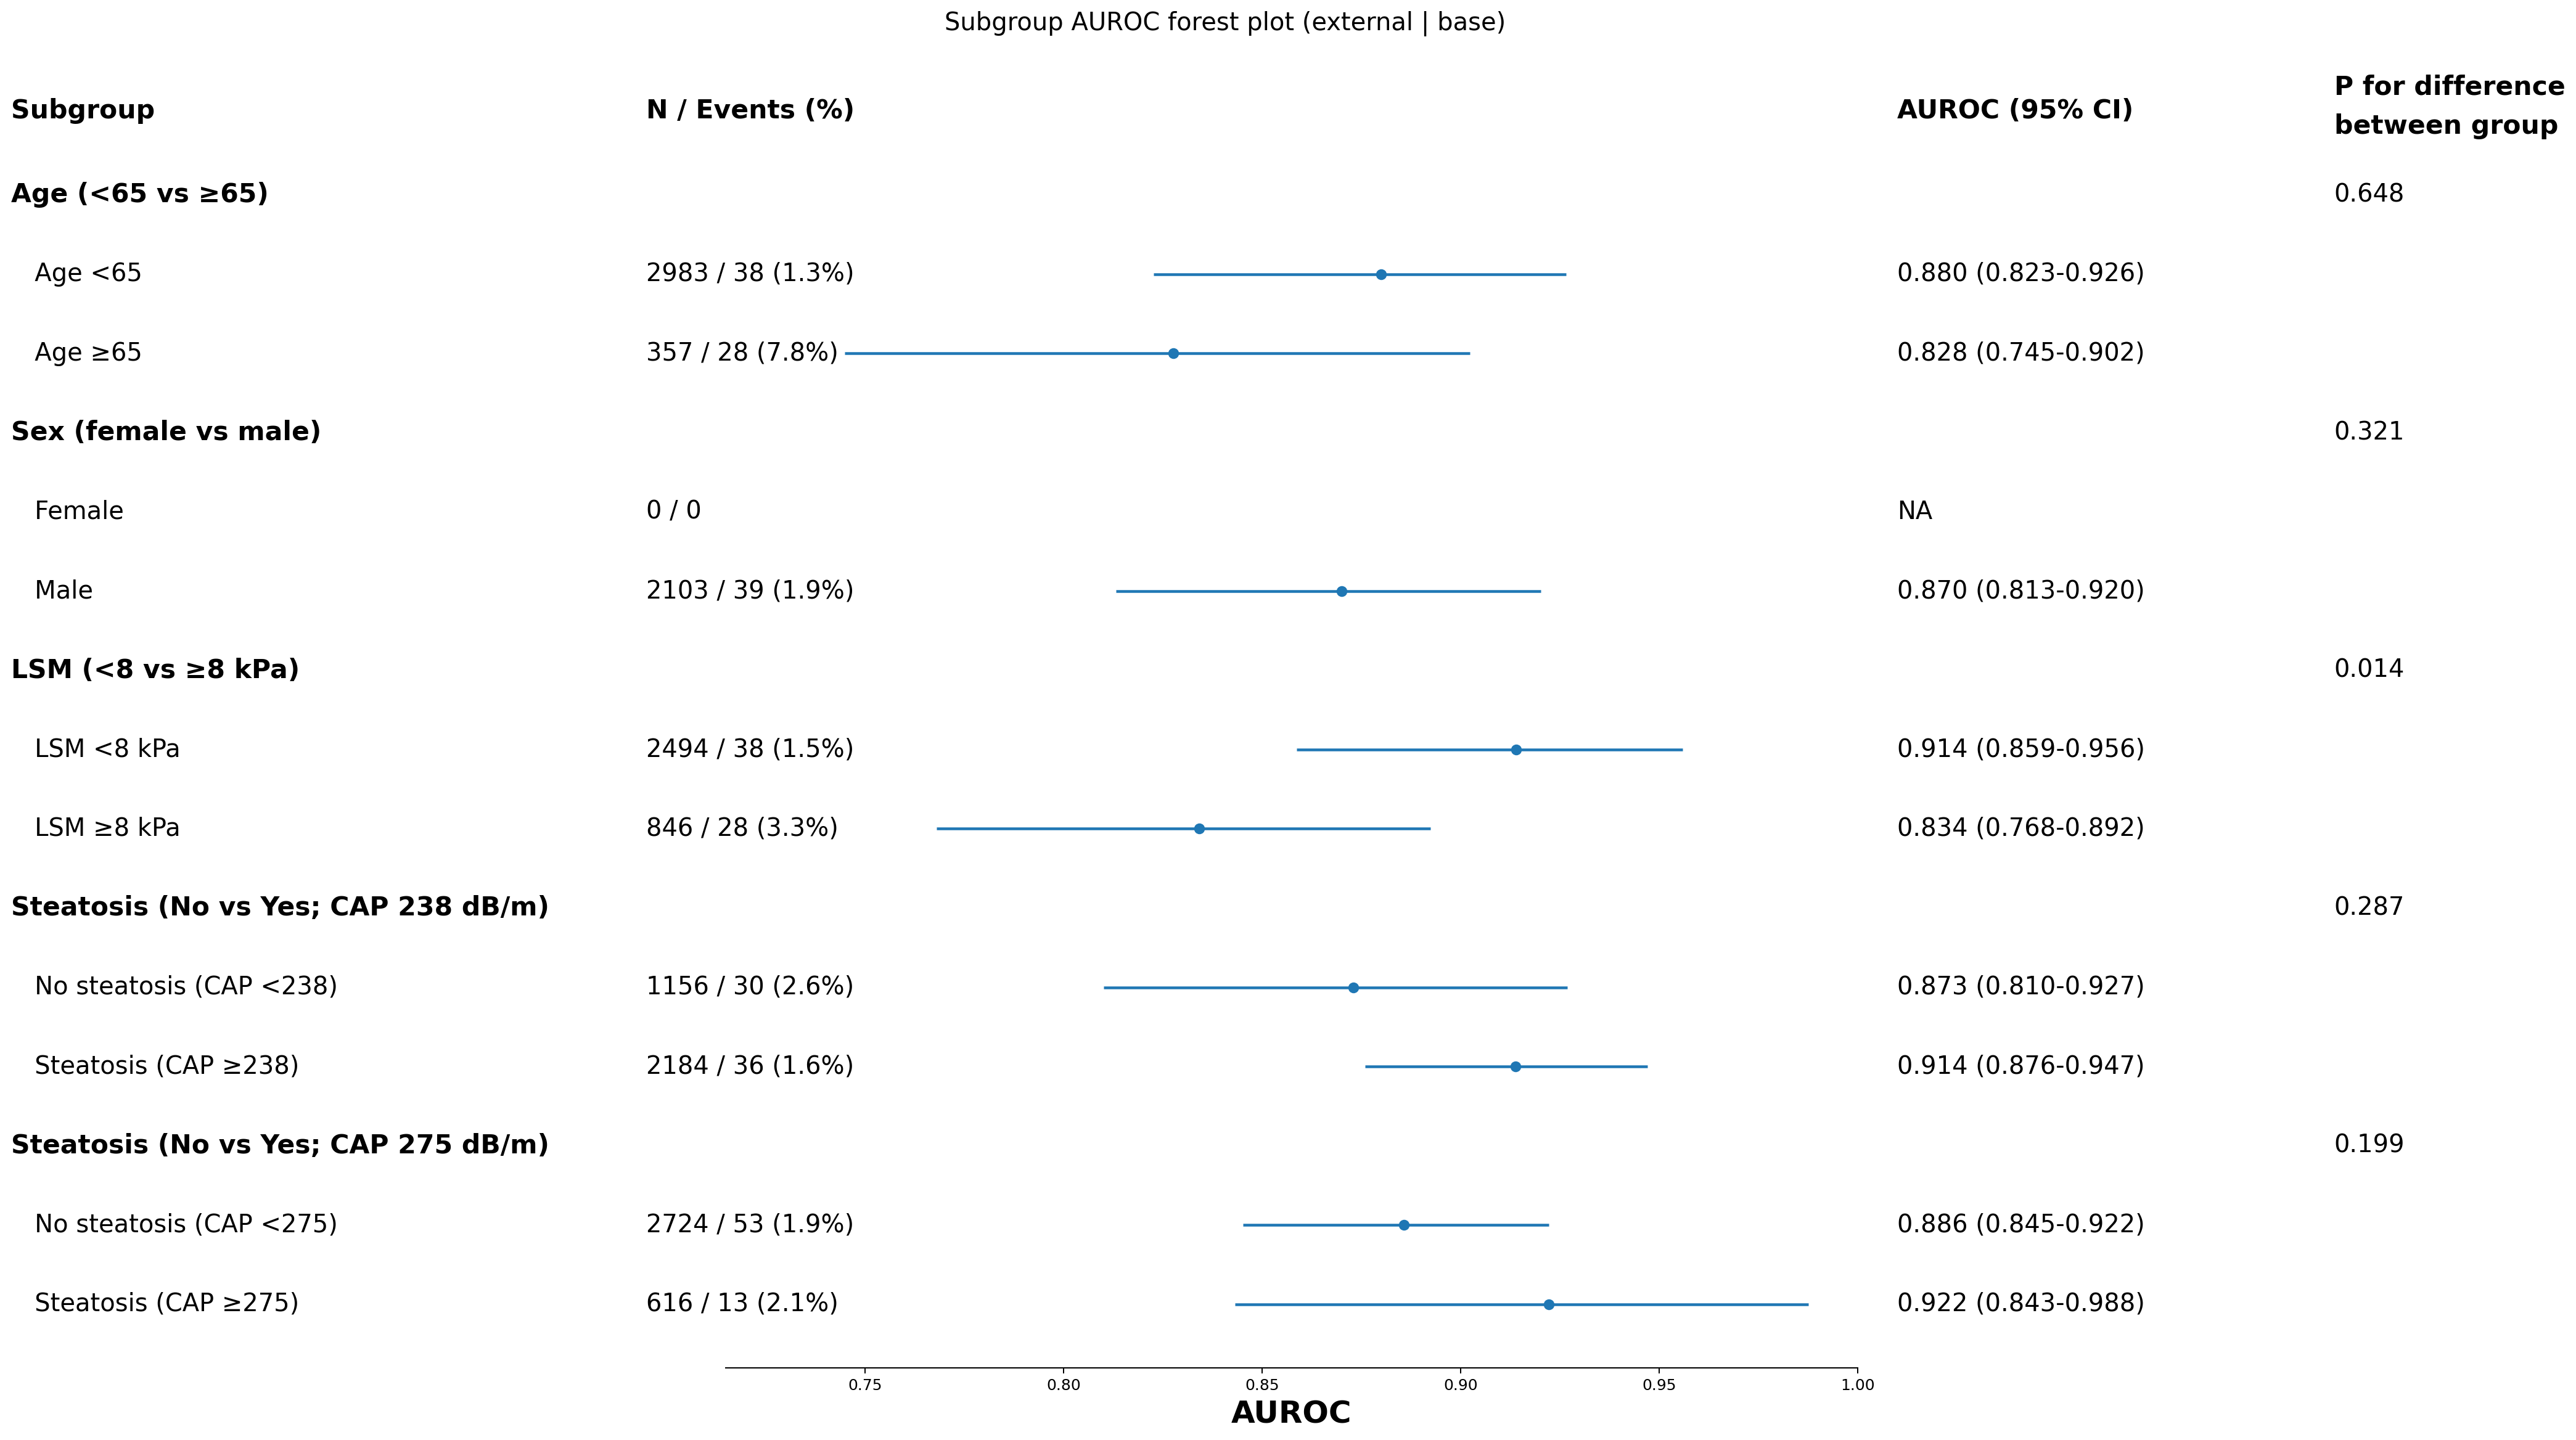

/home/ubuntu/ckd_output/subgroup_sensitivity_scen_B/forest_plots/forestplot__external__base_lsm.png


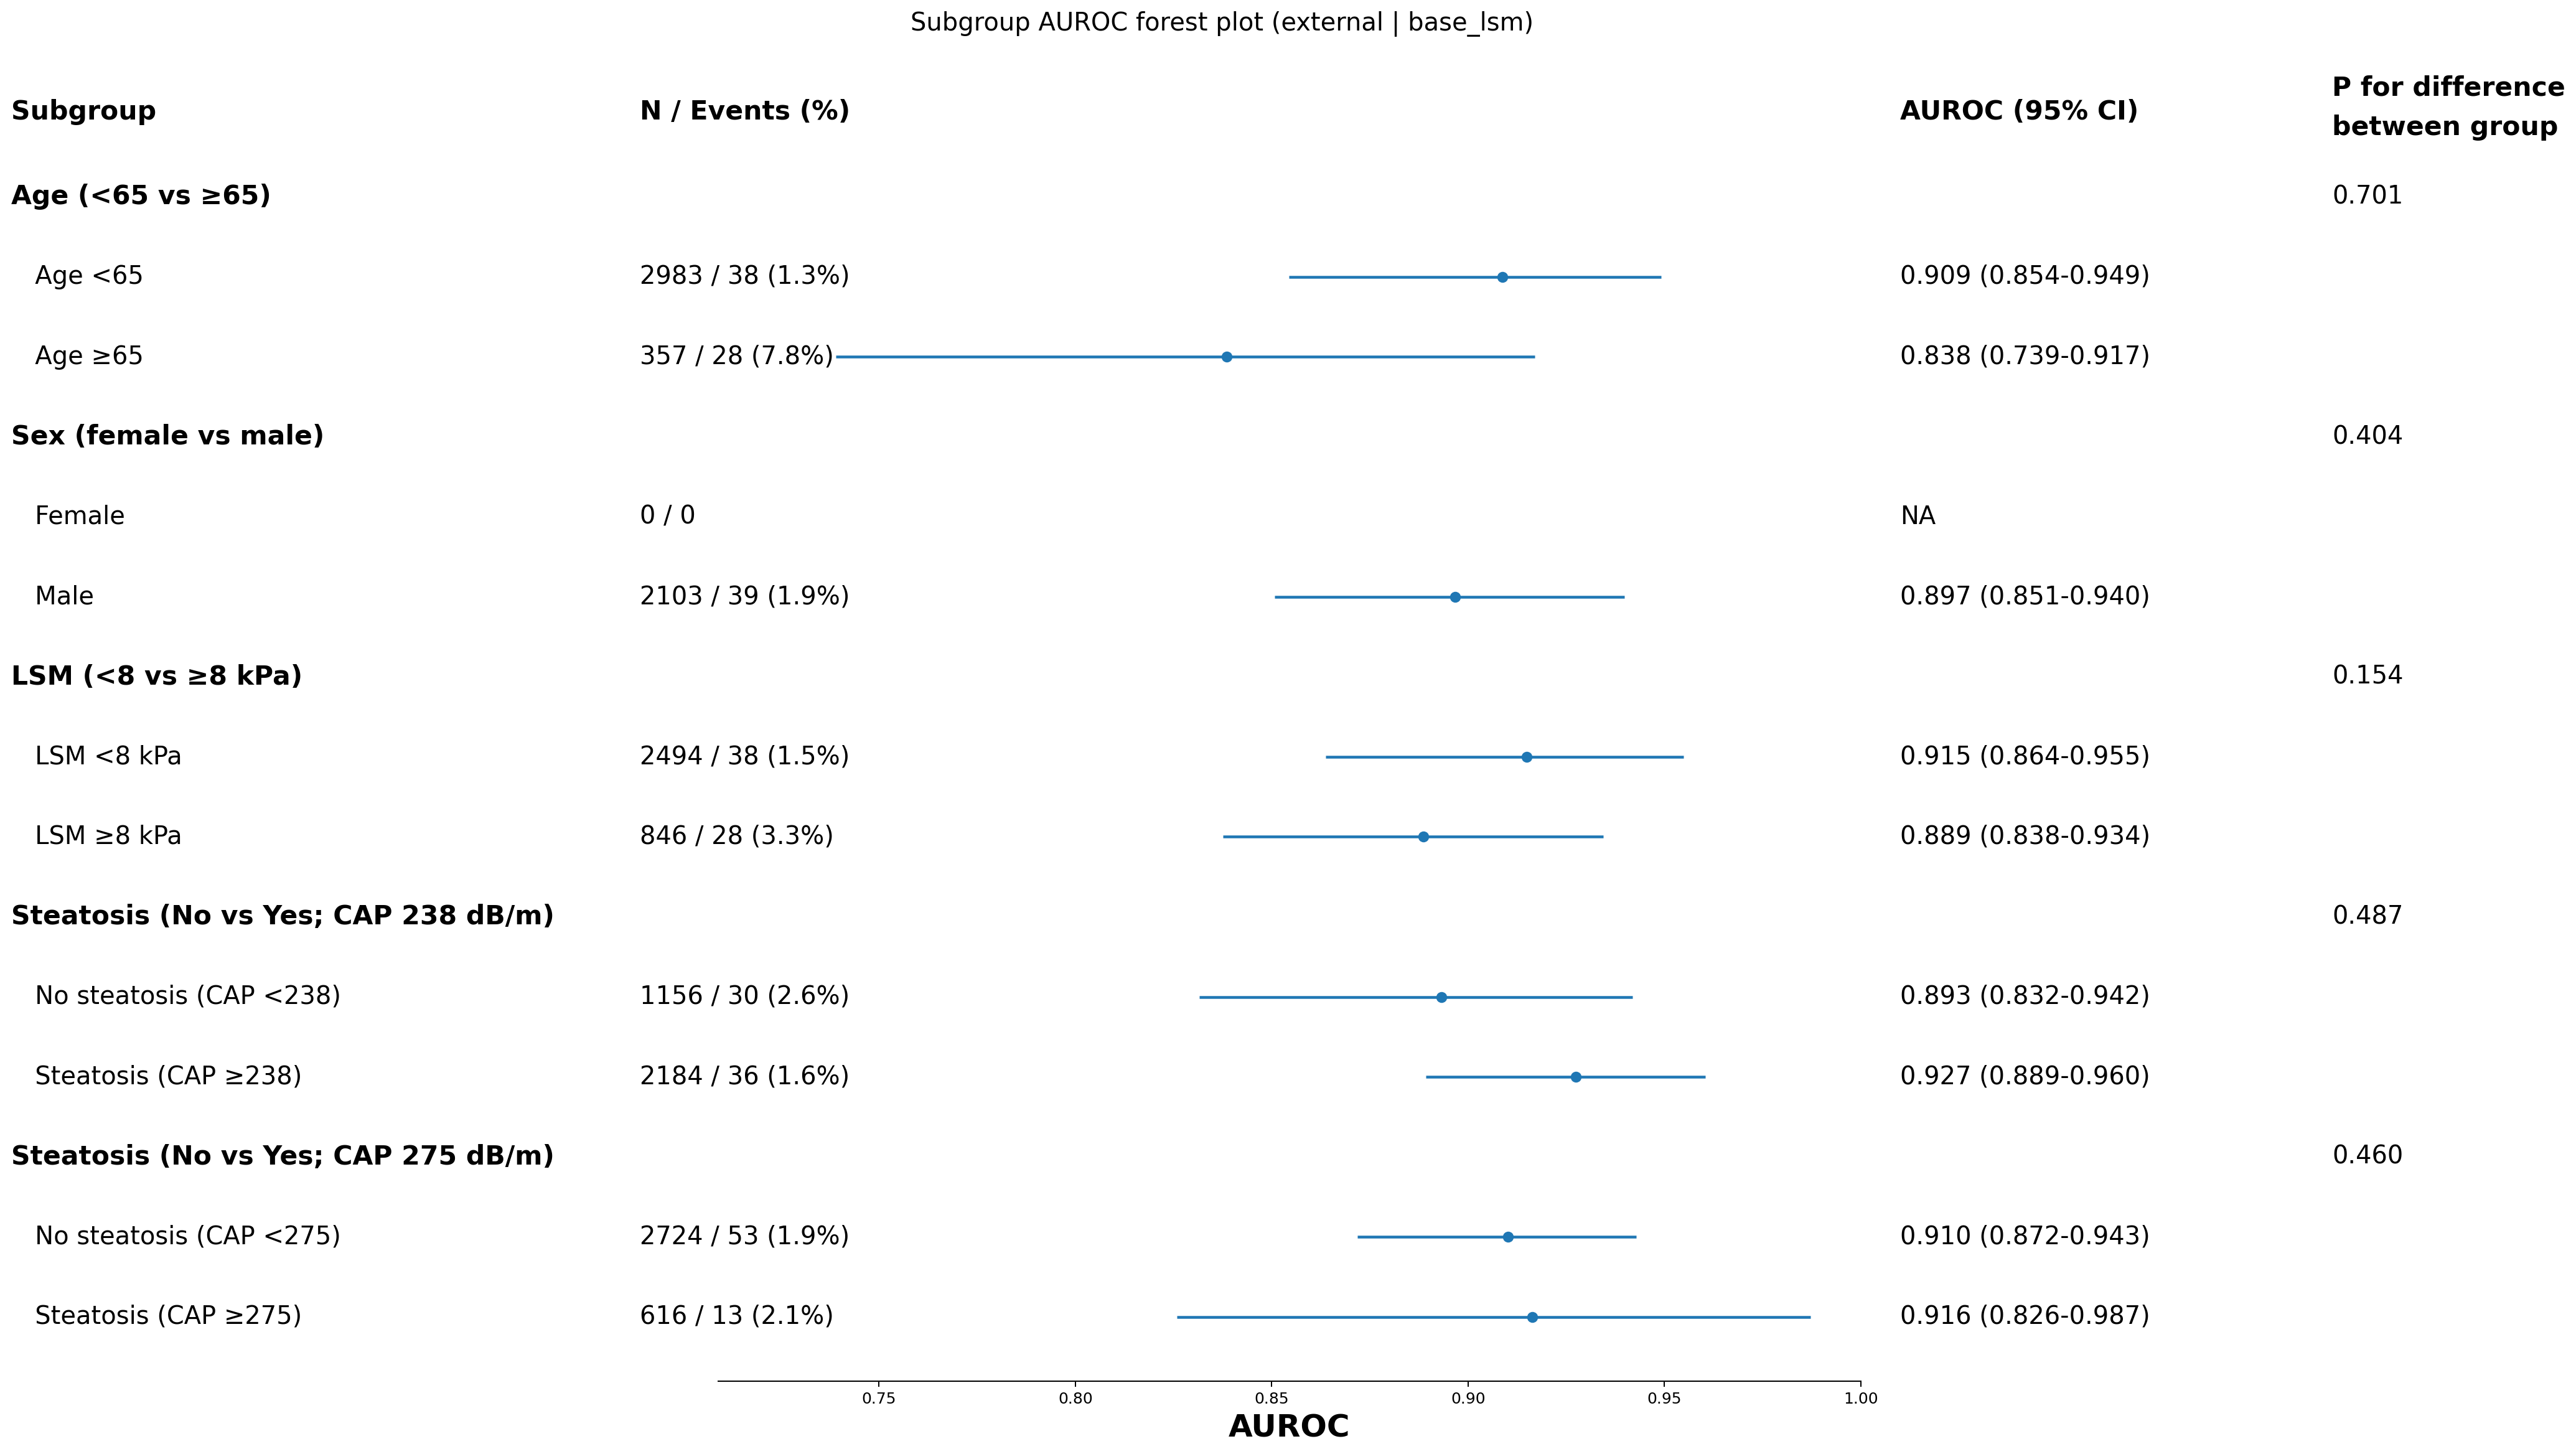

/home/ubuntu/ckd_output/subgroup_sensitivity_scen_B/forest_plots/forestplot__external__base_lsm_cap.png


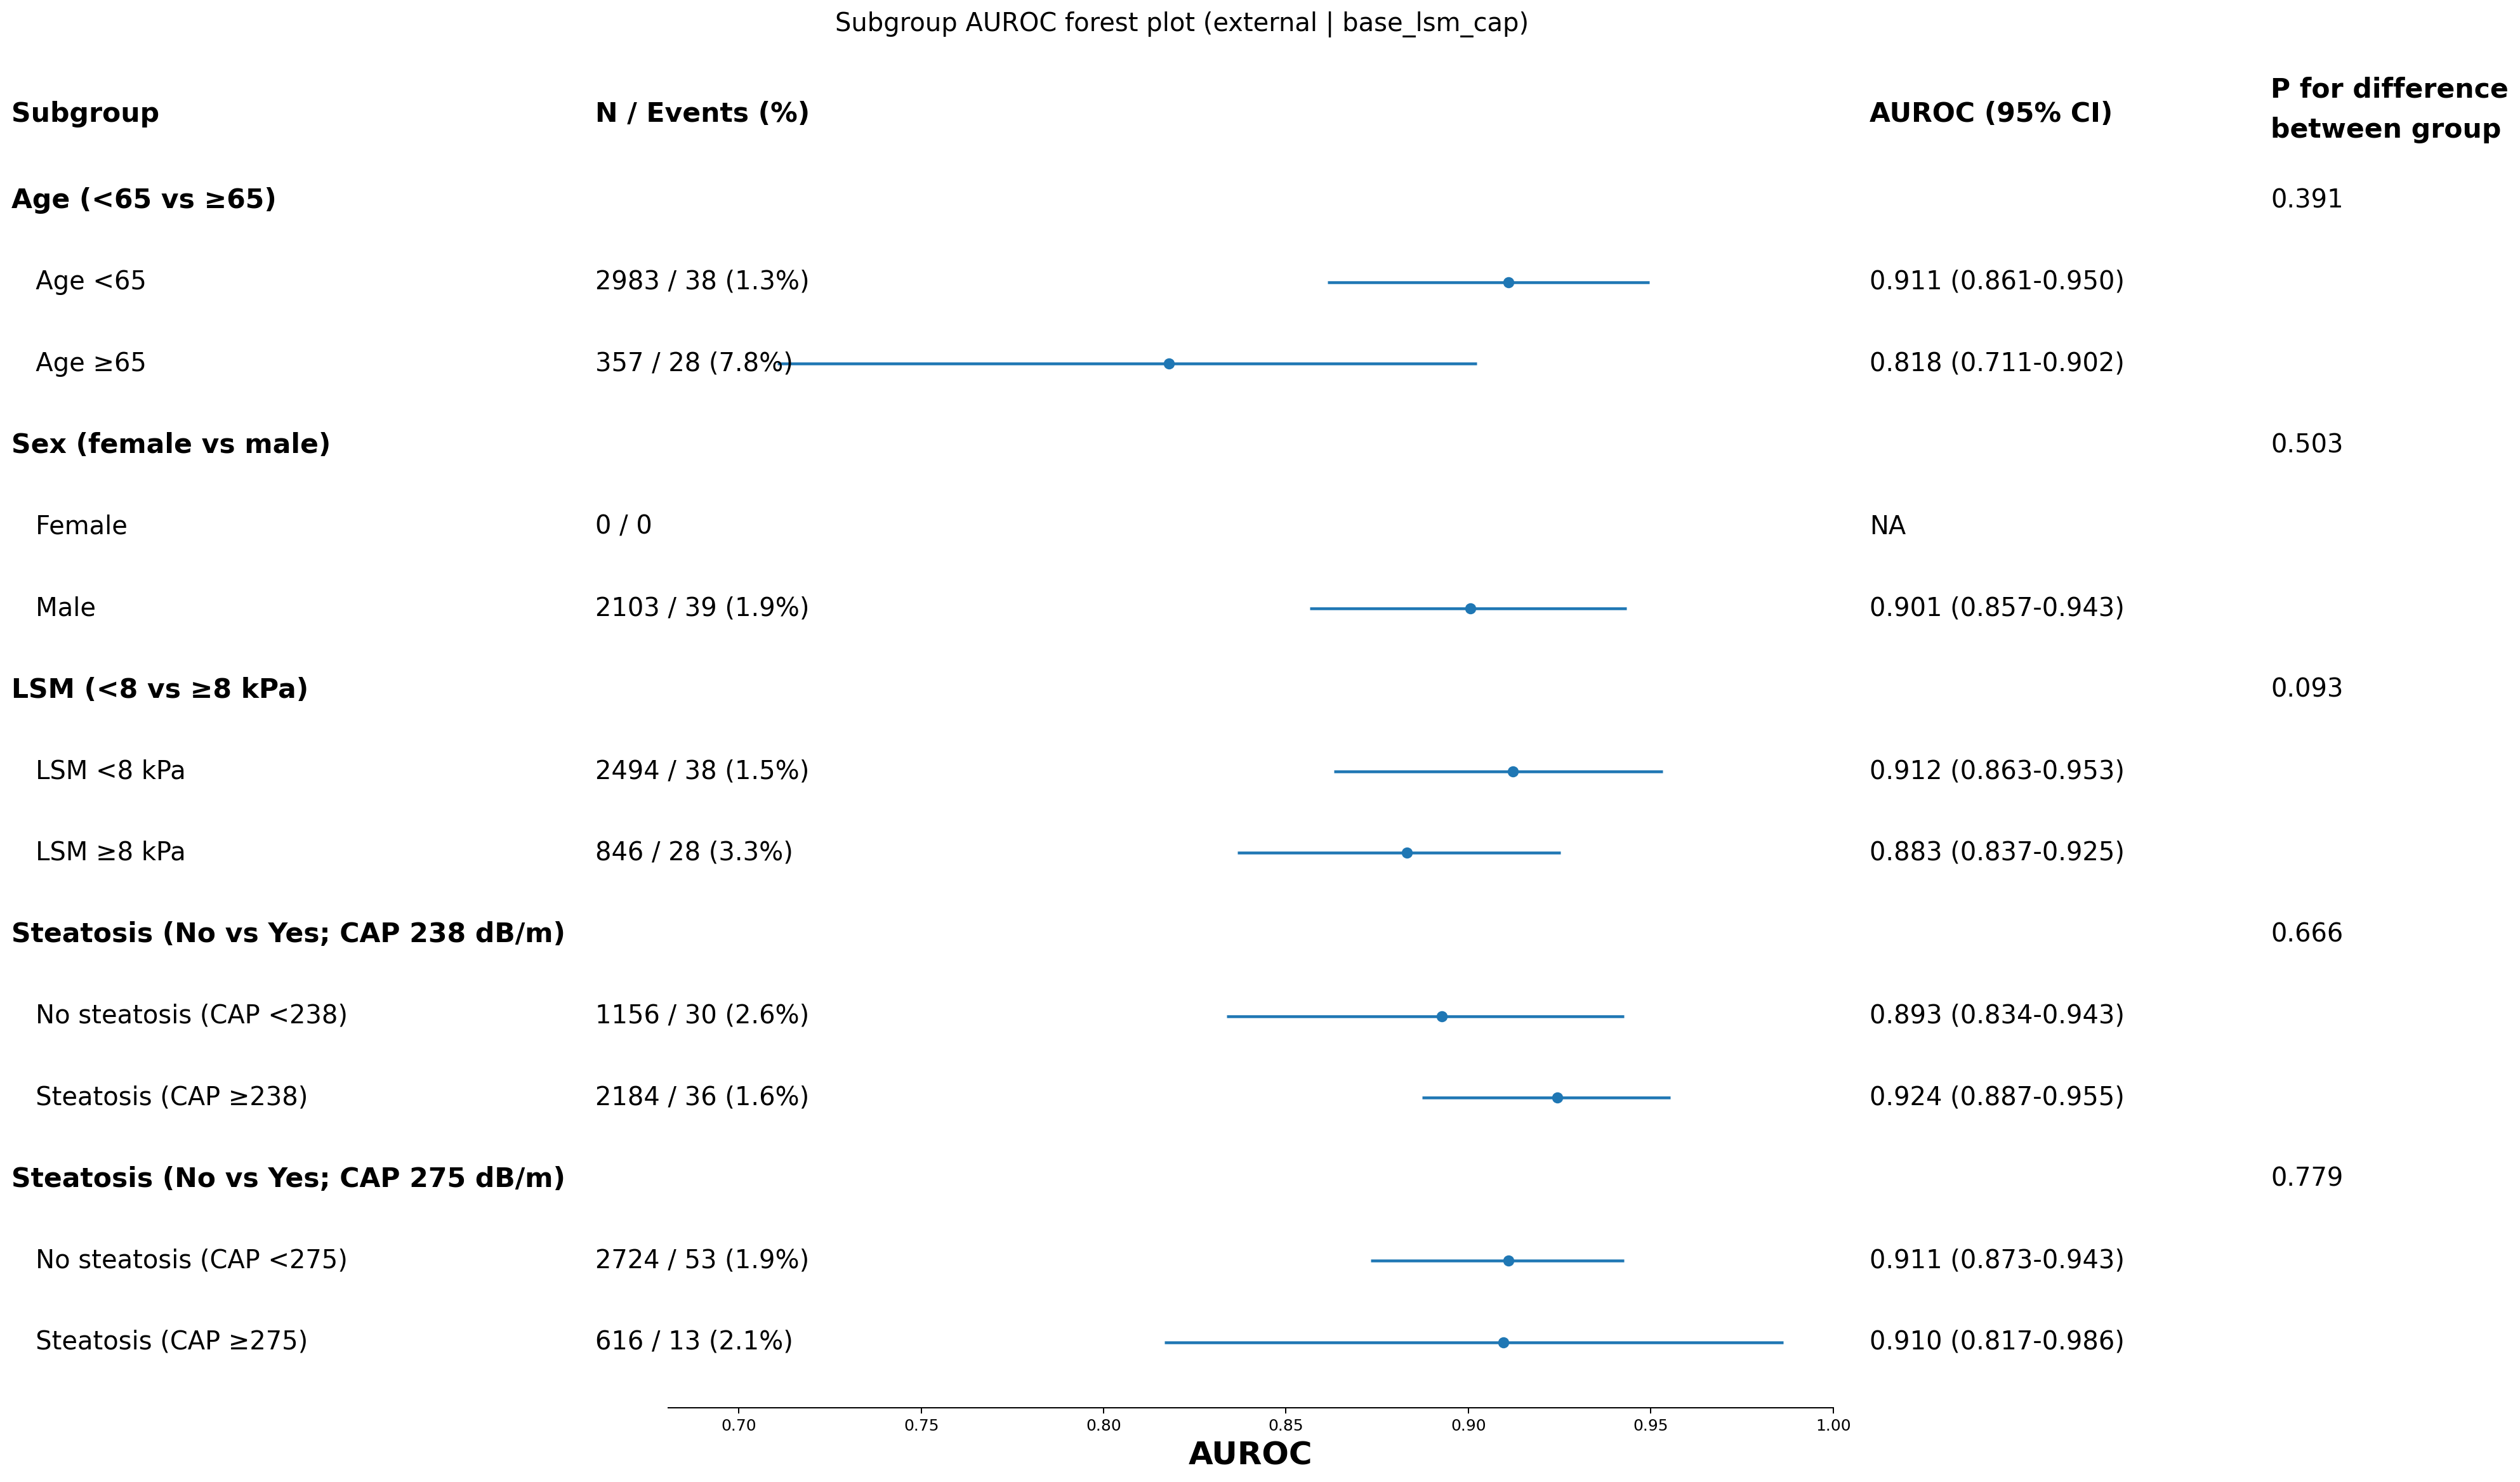

In [3]:
from IPython.display import Image
import glob

# 가장 최근 생성된 forest plot 미리보기
plots = sorted(glob.glob("/home/ubuntu/ckd_output/subgroup_sensitivity_scen_B/forest_plots/**/*.png", recursive=True))
for p in plots[:3]:  # 처음 3개만
    print(p)
    display(Image(p))